<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9827 entries, 0 to 9826
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9827 non-null   object 
 1   Title              9827 non-null   object 
 2   Overview           9827 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   int64  
 5   Vote_Average       9827 non-null   float64
 6   Original_Language  9827 non-null   object 
 7   Genre              9827 non-null   object 
 8   Poster_Url         9827 non-null   object 
dtypes: float64(2), int64(1), object(6)
memory usage: 691.1+ KB
Duplicated rows: 0
datetime64[ns]
int32
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9827 entries, 0 to 9826
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9827 non-null   int32  
 1   Title  

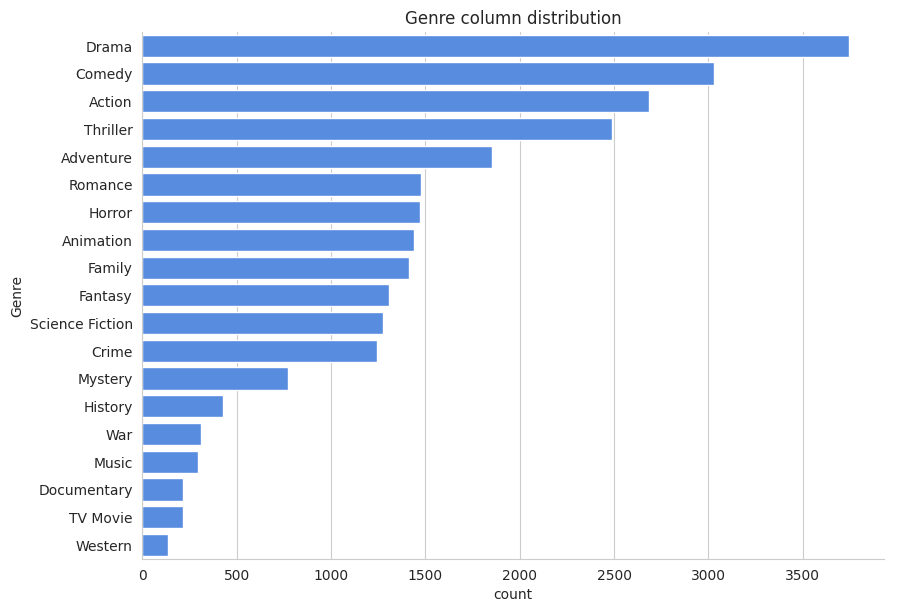

Most frequent genre: Drama (14.5% of rows)


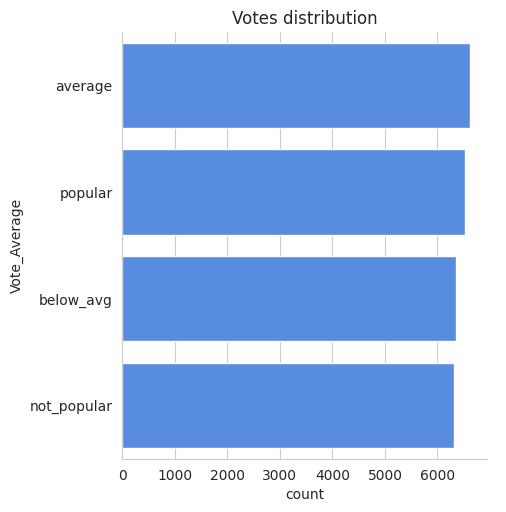

Vote_Average
average        6613
popular        6520
below_avg      6348
not_popular    6312
Name: count, dtype: int64
Vote_Average
average        25.6
popular        25.3
below_avg      24.6
not_popular    24.5
Name: proportion, dtype: float64

Genre share inside the 'popular' vote group (%):
Genre
Drama        20.1
Comedy        9.2
Animation     8.3
Action        8.1
Adventure     6.9
Romance       6.3
Thriller      6.0
Fantasy       5.8
Family        5.5
Crime         5.0
Name: proportion, dtype: float64


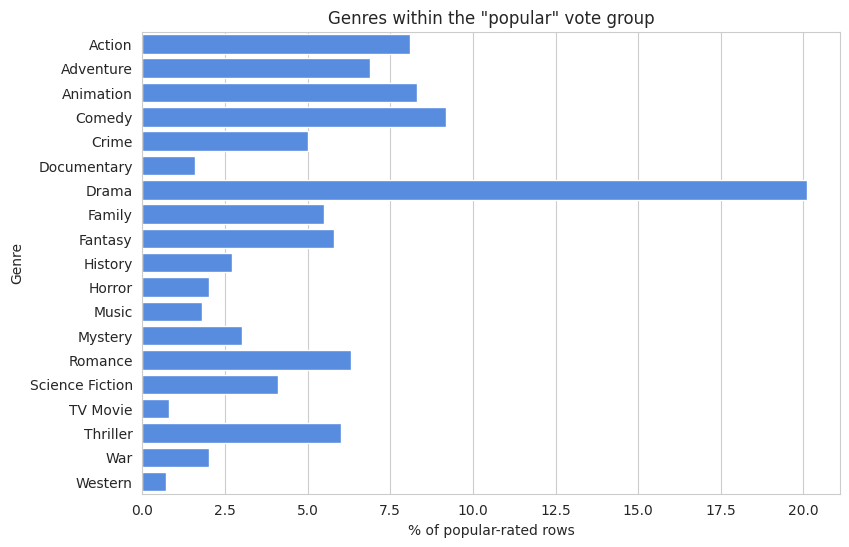

   Release_Date                    Title  Popularity  Vote_Count Vote_Average  \
0          2021  Spider-Man: No Way Home    5083.954        8940      popular   
1          2021  Spider-Man: No Way Home    5083.954        8940      popular   
2          2021  Spider-Man: No Way Home    5083.954        8940      popular   

             Genre  
0           Action  
1        Adventure  
2  Science Fiction  
       Release_Date                                 Title  Popularity  \
25787          2021  The United States vs. Billie Holiday      13.354   
25788          2021  The United States vs. Billie Holiday      13.354   
25789          2021  The United States vs. Billie Holiday      13.354   
25790          1984                               Threads      13.354   
25791          1984                               Threads      13.354   
25792          1984                               Threads      13.354   

       Vote_Count Vote_Average            Genre  
25787         152      averag

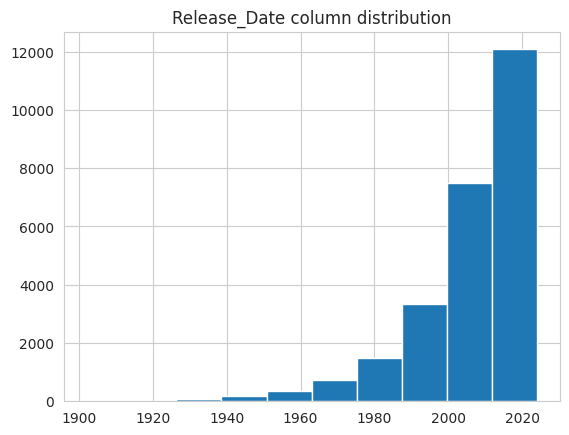

Year with the most movies: 2021 (713 movies)


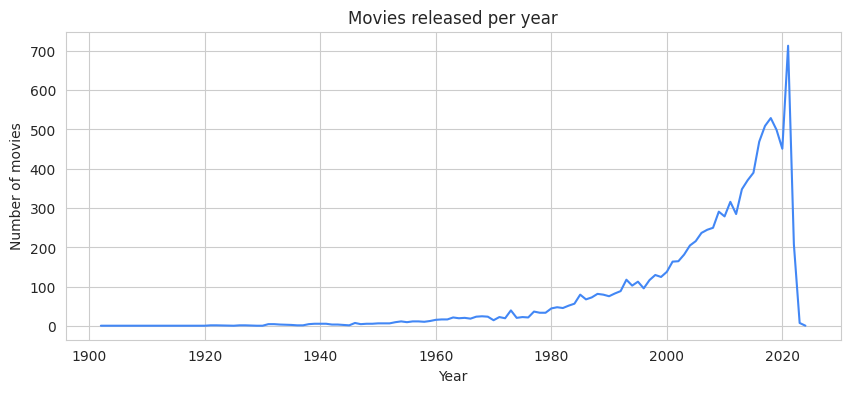


=========== CONCLUSION ===========
Q1: 'Drama' is the most frequent genre (14.5% of rows).
Q2: 'popular' group holds 6520 rows (25.3%); top genre in it: Drama (20.1%).
Q3: Highest popularity: Spider-Man: No Way Home -> Action, Adventure, Science Fiction
Q4: Lowest popularity: The United States vs. Billie Holiday, Threads
Q5: Year with most movies: 2021


In [6]:
# ---------- 1. Importing libraries ----------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# ---------- 2. Loading the data ----------
# Loading the uploaded local file directly
df = pd.read_csv('mymoviedb.csv', lineterminator='\n')
df.head()

# ---------- 3. Dataset info ----------
df.info()

# genres are separated by commas followed by whitespace
df['Genre'].head()

# duplicated rows
print("Duplicated rows:", df.duplicated().sum())

# summary statistics
df.describe()

"""
Exploration Summary
- 9827 rows and 9 columns
- No NaNs and no duplicated rows
- Release_Date must be cast to datetime and reduced to the year
- Overview, Original_Language and Poster_Url are not useful for analysis
- Popularity has noticeable outliers
- Vote_Average is better categorised for proper analysis
- Genre has comma-separated values with white spaces that need handling
"""

# ---------- 4. Data cleaning ----------
# 4.1 Cast Release_Date to datetime and keep only the year
df['Release_Date'] = pd.to_datetime(df['Release_Date'])
print(df['Release_Date'].dtypes)

df['Release_Date'] = df['Release_Date'].dt.year
print(df['Release_Date'].dtypes)
df.info()

# 4.2 Drop columns we do not need
cols = ['Overview', 'Original_Language', 'Poster_Url']
df.drop(cols, axis=1, inplace=True)
print(df.columns)
df.head()

# 4.3 Categorise Vote_Average into 4 quartile-based groups
def catigorize_col(df, col, labels):
    """
    Categorises a column based on its quartiles.

    Args:
        df     - dataframe we are processing
        col    - name of the column to categorise
        labels - list of labels from min to max
    Returns:
        df with the categorised column
    """
    edges = [df[col].describe()['min'],
             df[col].describe()['25%'],
             df[col].describe()['50%'],
             df[col].describe()['75%'],
             df[col].describe()['max']]
    # include_lowest=True keeps movies sitting exactly on the minimum edge
    # (Vote_Average = 0). Without it they become NaN and get dropped.
    df[col] = pd.cut(df[col], edges, labels=labels,
                     duplicates='drop', include_lowest=True)
    return df

labels = ['not_popular', 'below_avg', 'average', 'popular']
catigorize_col(df, 'Vote_Average', labels)
print(df['Vote_Average'].unique())
df.head()

df['Vote_Average'].value_counts()

# 4.4 Drop NaNs (if any) and confirm
df.dropna(inplace=True)
print(df.isna().sum())

# 4.5 Split genres into a list, then explode: one genre per row
df['Genre'] = df['Genre'].str.split(', ')
df = df.explode('Genre').reset_index(drop=True)
df.head()

# cast Genre to category
df['Genre'] = df['Genre'].astype('category')
print(df['Genre'].dtypes)

df.info()

df.nunique()
print(f"Clean dataset: {df.shape[1]} columns and {df.shape[0]} rows")

# ---------- 5. Data visualisation ----------
# Q1: What is the most frequent genre in the dataset?
print(df['Genre'].describe())

sns.catplot(y='Genre', data=df, kind='count',
            order=df['Genre'].value_counts().index,
            color='#4287f5', height=6, aspect=1.5)
plt.title('Genre column distribution')
plt.show()

top_genre = df['Genre'].value_counts().idxmax()
top_pct = df['Genre'].value_counts(normalize=True).max() * 100
print(f"Most frequent genre: {top_genre} ({top_pct:.1f}% of rows)")

# ---------------------------------------------------------------
# Q2: Which genres have the highest votes?
# (a) distribution of the Vote_Average categories
sns.catplot(y='Vote_Average', data=df, kind='count',
            order=df['Vote_Average'].value_counts().index,
            color='#4287f5')
plt.title('Votes distribution')
plt.show()

print(df['Vote_Average'].value_counts())
print((df['Vote_Average'].value_counts(normalize=True) * 100).round(1))

# (b) which genres dominate the "popular" vote group?
popular = df[df['Vote_Average'] == 'popular']
pop_share = (popular['Genre'].value_counts(normalize=True) * 100).round(1)
print("\nGenre share inside the 'popular' vote group (%):")
print(pop_share.head(10))

plt.figure(figsize=(9, 6))
sns.barplot(x=pop_share.values, y=pop_share.index, color='#4287f5')
plt.xlabel('% of popular-rated rows')
plt.title('Genres within the "popular" vote group')
plt.show()

# ---------------------------------------------------------------
# Q3: Which movie got the highest popularity? What are its genres?
print(df[df['Popularity'] == df['Popularity'].max()])

# Q4: Which movie got the lowest popularity? What are its genres?
print(df[df['Popularity'] == df['Popularity'].min()])

# ---------------------------------------------------------------
# Q5: Which year has the most movies?
# (a) histogram (as in the original notebook)
df['Release_Date'].hist()
plt.title('Release_Date column distribution')
plt.show()

# (b) exact year counts. Rows are exploded per genre, so count UNIQUE movies.
movies_per_year = (df.drop_duplicates(subset=['Title', 'Release_Date'])
                     ['Release_Date'].value_counts().sort_index())
best_year = movies_per_year.idxmax()
print(f"Year with the most movies: {best_year} ({movies_per_year.max()} movies)")

plt.figure(figsize=(10, 4))
plt.plot(movies_per_year.index, movies_per_year.values, color='#4287f5')
plt.title('Movies released per year')
plt.xlabel('Year'); plt.ylabel('Number of movies')
plt.show()

# ---------- 6. Conclusion ----------
print("\n=========== CONCLUSION ===========")
print(f"Q1: '{top_genre}' is the most frequent genre ({top_pct:.1f}% of rows).")
print(f"Q2: 'popular' group holds {len(popular)} rows "
      f"({len(popular)/len(df)*100:.1f}%); top genre in it: {pop_share.index[0]} ({pop_share.iloc[0]}%).")
mx = df[df['Popularity'] == df['Popularity'].max()]
mn = df[df['Popularity'] == df['Popularity'].min()]
print(f"Q3: Highest popularity: {mx['Title'].iloc[0]} -> {', '.join(mx['Genre'].astype(str))}")
print(f"Q4: Lowest popularity: {', '.join(mn['Title'].unique())}")
print(f"Q5: Year with most movies: {best_year}")